# LIS 4369: Extensible Enterprise Solutions
## Assignment 4 – Financial Analysis
Developer: Khushi Patel

Program Requirements:
- Get
- Clean
- Prepare
- Analyze
- Visualize

In [1]:
import sys
import os
import pandas as pd
import pandas_datareader as pdr
import yfinance as yf
import matplotlib.pyplot as plt
from matplotlib import style
from datetime import datetime as dt

print(sys.version)
print(os.environ['CONDA_DEFAULT_ENV'])

3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:30:20) [Clang 20.1.8 ]
base


In [2]:
%run demo.py


Print number of records: 
2608
Index(['DJIA', 'SP500'], dtype='str')

Print data frame: 
                DJIA    SP500
DATE                         
2016-11-14  18868.69  2164.20
2016-11-15  18923.06  2180.39
2016-11-16  18868.14  2176.94
2016-11-17  18903.82  2187.12
2016-11-18  18867.93  2181.90
...              ...      ...
2026-11-05  51523.06  7353.73
2026-11-06  51285.73  7376.86
2026-11-09  52389.75  7549.94
2026-11-10  52231.89  7520.93
2026-11-11  52486.49  7619.38

[2608 rows x 2 columns]

Print first five lines: 
                DJIA    SP500
DATE                         
2016-11-14  18868.69  2164.20
2016-11-15  18923.06  2180.39
2016-11-16  18868.14  2176.94
2016-11-17  18903.82  2187.12
2016-11-18  18867.93  2181.90

Print last five lines: 
                DJIA    SP500
DATE                         
2026-11-05  51523.06  7353.73
2026-11-06  51285.73  7376.86
2026-11-09  52389.75  7549.94
2026-11-10  52231.89  7520.93
2026-11-11  52486.49  7619.38

Print first 2 lines: 
 

In [3]:
ticker = "^SPX"
end = dt.date.today()
start = dt.datetime(year=end.year-1, month=end.month, day=end.day)

df_spx_index = yf.download(ticker, start=start, end=end, progress=False)

type(df_spx_index)

pandas.DataFrame

In [4]:
# 4. print DataFrame summary
print(df_spx_index.info())

<class 'pandas.DataFrame'>
DatetimeIndex: 251 entries, 2025-11-12 to 2026-11-11
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, ^SPX)   251 non-null    float64
 1   (High, ^SPX)    251 non-null    float64
 2   (Low, ^SPX)     251 non-null    float64
 3   (Open, ^SPX)    251 non-null    float64
 4   (Volume, ^SPX)  251 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 11.8 KB
None


In [5]:
# 5. note: when changing col names using list, order of list must align with col positions
df_spx_index.columns = ['Close', 'High', 'Low', 'Open', 'Volume']

# note: col name change
print(df_spx_index.info())

<class 'pandas.DataFrame'>
DatetimeIndex: 251 entries, 2025-11-12 to 2026-11-11
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   251 non-null    float64
 1   High    251 non-null    float64
 2   Low     251 non-null    float64
 3   Open    251 non-null    float64
 4   Volume  251 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 11.8 KB
None


In [6]:
# 6. print first/last 5 records of S&P500 index 1-year price history
df_spx_index

,Close,High,Low,Open,Volume
Date,,,,,
2025-11-12,6850.919922,6869.910156,6829.620117,6867.770020,5293610000
2025-11-13,6737.490234,6828.049805,6724.720215,6826.470215,5473720000
2025-11-14,6734.109863,6774.310059,6646.870117,6672.140137,5042660000
2025-11-17,6672.410156,6754.500000,6638.899902,6713.609863,5204220000
2025-11-18,6617.319824,6666.629883,6574.319824,6641.189941,5159390000
...,...,...,...,...,...
2026-11-05,7353.729980,7681.290039,7350.350098,7678.720215,7654840000
2026-11-06,7376.859863,7444.200195,7369.549805,7377.649902,5701900000
2026-11-09,7549.939941,7577.390137,7422.240234,7422.240234,5819360000


<Axes: title={'center': 'S&P500 index 1-year price history'}, xlabel='Date'>

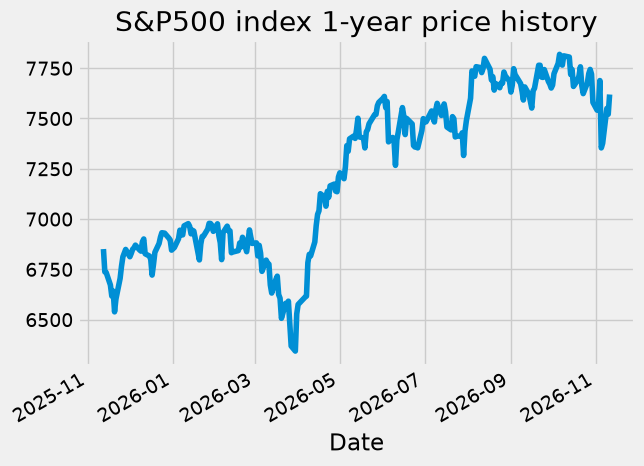

In [7]:
# 7. plot S&P500 index 1-year price history closing prices
df_spx_index['Close'].plot(title='S&P500 index 1-year price history')

In [8]:
# 8. get unemployment data by date (2000 - present)
start = dt.datetime(2000, 1, 1)
end = dt.datetime.now()

df = pdr.DataReader(['LNS13023653', 'LNS13026638'], 'fred', start, end)
df = df.rename(columns={'LNS13023653':'Jobs Lost - Layoff', 'LNS13026638':'Jobs Lost - Permanent'})
df.columns # display new column names

Index(['Jobs Lost - Layoff', 'Jobs Lost - Permanent'], dtype='str')

In [9]:
# a. print number of data prints
print(len(df))

322


In [10]:
# b. display first/last 5 records formatted with thousand separator
df = df*1000 # convert to actual values

df_formatted = pd.concat([df.head(5), df.tail(5)]).style.format('{:,.0f}')
df_formatted
 

,Jobs Lost - Layoff,Jobs Lost - Permanent
DATE,,
2000-01-01 00:00:00,"753,000","1,165,000"
2000-02-01 00:00:00,"849,000","1,171,000"
2000-03-01 00:00:00,"816,000","1,155,000"
2000-04-01 00:00:00,"707,000","1,083,000"
2000-05-01 00:00:00,"868,000","1,076,000"
2026-06-01 00:00:00,"768,000","1,769,000"
2026-07-01 00:00:00,"921,000","1,715,000"
2026-08-01 00:00:00,"839,000","1,777,000"
2026-09-01 00:00:00,"845,000","1,750,000"


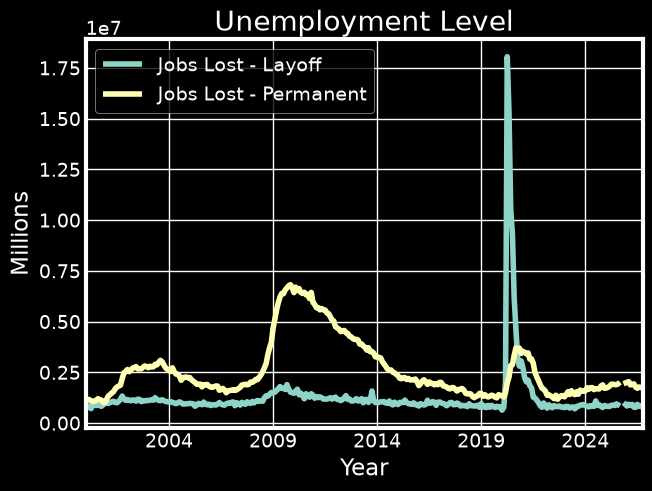

In [11]:
# c. plot unemployment numbers by date
plt.style.use('dark_background') # use different style

df['Jobs Lost - Layoff'].plot()
df['Jobs Lost - Permanent'].plot()
plt.title('Unemployment Level')
plt.xlabel('Year')
plt.ylabel('Millions')
plt.legend()
plt.show()


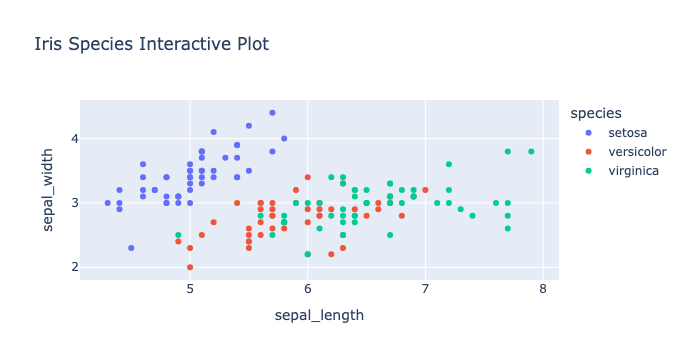

In [12]:
# d. demo interactive plot using Plotly Express and built-in dataset
import plotly.express as px

# i. prepare data
df_iris = px.data.iris()

# ii. create scatter plot using Plotly Express scatter() function
# x-axis: 'sepal_length'; y-axis: 'sepal_width'; 'species' determines point color
fig = px.scatter(df_iris, title="Iris Species Interactive Plot", x="sepal_length", y="sepal_width", color="species")

# iii. display plot
fig.show()


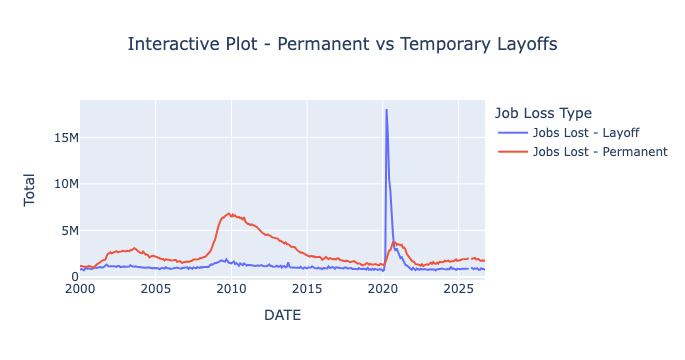

In [13]:
# e. create employment interactive visualization
import plotly.express as px

# set line() function parameters
fig = px.line(df, y=['Jobs Lost - Layoff',
                     'Jobs Lost - Permanent'],
              title='Interactive Plot - Permanent vs Temporary Layoffs',
              labels={'value':'Total',
                      'variable':'Job Loss Type'})

# center title, and make single hover label appear for each point per trace as cursor ('x unified')
fig.update_layout(title_x=0.5, hovermode='x unified')
fig.show()


In [14]:
# f. save to unemployment.csv
df.to_csv('unemployment.csv')

In [15]:
# 9. display inflation percentage values by date

start = dt.datetime (1960, 1, 1)
end = dt.datetime.now()

df = pdr.DataReader(['FPCPITOTLZGUSA'], 'fred', start, end)
df = df.rename(columns={'FPCPITOTLZGUSA':'U.S. Inflation'})
df.columns # display new column names


Index(['U.S. Inflation'], dtype='str')

In [16]:
# a. display number of data points
print(len(df))

65


In [17]:
# b. display first/last 5 records formatted to two decimal places
df_formatted = pd.concat([df.head(5), df.tail(5)]).style.format('{:,.2f}')
df_formatted

,U.S. Inflation
DATE,
1960-01-01 00:00:00,1.46
1961-01-01 00:00:00,1.07
1962-01-01 00:00:00,1.20
1963-01-01 00:00:00,1.24
1964-01-01 00:00:00,1.28
2020-01-01 00:00:00,1.23
2021-01-01 00:00:00,4.70
2022-01-01 00:00:00,8.00
2023-01-01 00:00:00,4.12


In [18]:
# c. show changes on month-to-month basis
df_diff = df['U.S. Inflation'].diff()
df_diff # why does first row contain Nan? ans: gap in dataset

DATE
1960-01-01         NaN
1961-01-01   -0.387252
1962-01-01    0.128049
1963-01-01    0.040896
1964-01-01    0.039242
                ...   
2020-01-01   -0.578626
2021-01-01    3.464274
2022-01-01    3.304941
2023-01-01   -3.886461
2024-01-01   -1.166813
Name: U.S. Inflation, Length: 65, dtype: float64

In [19]:
# d. format changes on month-to-month basis to two decimal places
rounded_number = round(df_diff, 2)
print(rounded_number)

DATE
1960-01-01     NaN
1961-01-01   -0.39
1962-01-01    0.13
1963-01-01    0.04
1964-01-01    0.04
              ... 
2020-01-01   -0.58
2021-01-01    3.46
2022-01-01    3.30
2023-01-01   -3.89
2024-01-01   -1.17
Name: U.S. Inflation, Length: 65, dtype: float64


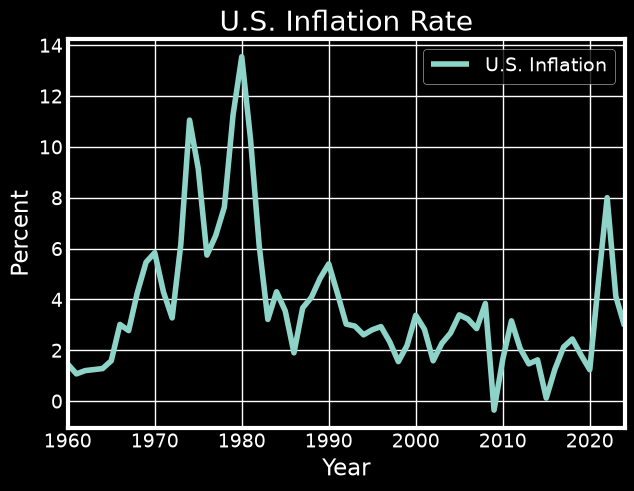

In [20]:
# e. plot inflation numbers by date
plt.style.use('dark_background')

df['U.S. Inflation'].plot()
plt.title('U.S. Inflation Rate')
plt.xlabel('Year')
plt.ylabel('Percent')
plt.legend()
plt.show()


In [21]:
# f. save to inflation.csv
df.to_csv('inflation.csv')